# Captum tour: training examples

The two models are described in `01_data_and_models`.

In [1]:
from toy import *  # shared setup: data, the two models (trained once, then cached), helpers

**Question**: which training examples is each layer still being pushed by?

## 17. `TracInCP` restricted to one layer: how hard training still pushes it

```python
g[i] = gradient of example i's loss w.r.t. fc2's weights     # 195 numbers in narrow, 4160 in wide
tracin = TracInCP(model, data, checkpoints, layers=["fc2"])
influence[i, j]   = g[i] · g[j]                             # does example i help example j?
self_influence[i] = g[i] · g[i]                             # how hard example i still pushes fc2
push = mean(self_influence) / number of fc2 weights         # per layer, per checkpoint   → plot
```

A converging layer: the push shrinks. A stuck layer: it stays high or grows.

TracInCP at 31 checkpoints x 3 layers x 2 models in 0s


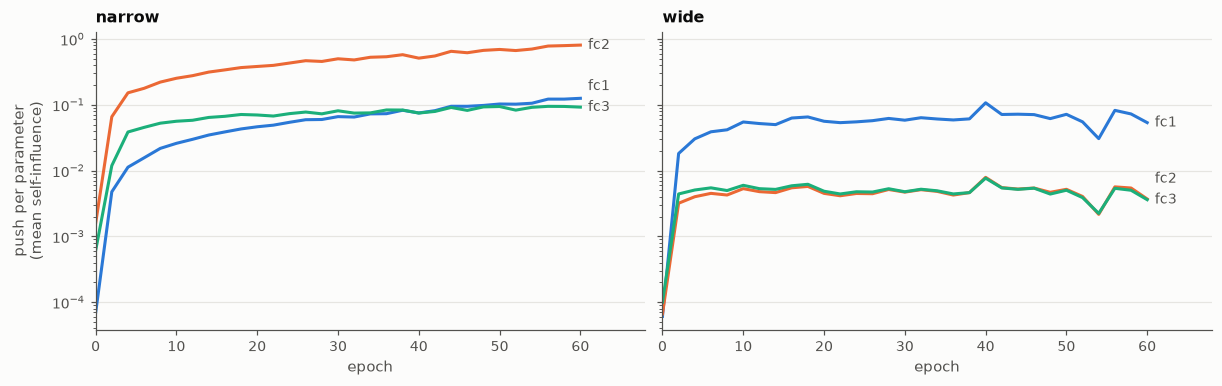

In [2]:

t0 = time.time()
push = pd.DataFrame([dict(model=name, epoch=e, layer=layer,
                          per_param=layer_push(w, CKPTS[name][e], layer).mean().item() / n_params(w, layer))
                     for name, w in WIDTH.items() for e in EPOCH_GRID for layer in LAYERS])
print(f"TracInCP at {len(EPOCH_GRID)} checkpoints x 3 layers x 2 models in {time.time() - t0:.0f}s")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, name in zip(axes, ["narrow", "wide"]):
    for layer in LAYERS:
        d = push[(push.model == name) & (push.layer == layer)]
        ax.plot(d.epoch, d.per_param, color=LAYER_COLOR[layer])
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_xlim(0, 68)
    ax.set_title(name, loc="left")
for ax, name in zip(axes, ["narrow", "wide"]):
    last = push[(push.model == name) & (push.epoch == EPOCHS)]
    end_labels(ax, [(EPOCHS, v, layer) for layer, v in zip(last.layer, last.per_param)])
axes[0].set_ylabel("push per parameter\n(mean self-influence)")
plt.show()

* Narrow `fc2`: pushed 6–9× harder per parameter than its neighbours, and the push keeps growing all run.
* Wide model: the push stays flat or falls. `fc1`'s push per parameter is high in both models (it sees the raw
  features), so a high push alone is not a capacity signal. It has to come with saturation and a stalled loss (§25).

## 18. Which examples: `self_influence`, `influence(k=…)`, `TracInCPFast`, `TracInCPFastRandProj`

```python
plot: mean self_influence on fc2 per class, narrow vs wide

tracin.influence(example, k=5, proponents=True)     # 5 training examples with the largest g[i] · g[example]
tracin.influence(example, k=5, proponents=False)    # 5 most negative: they pull the other way
TracInCPFast(model, final_fc_layer=model.fc4, ...)  # the same with only the last layer's gradients (cheap)
TracInCPFastRandProj(..., projection_dim=8)         # + random projection and nearest-neighbour search,
                                                    #   for huge training sets
```

`TracInCPFastRandProj`'s default index needs the `annoy` package, so a brute-force one is passed in.

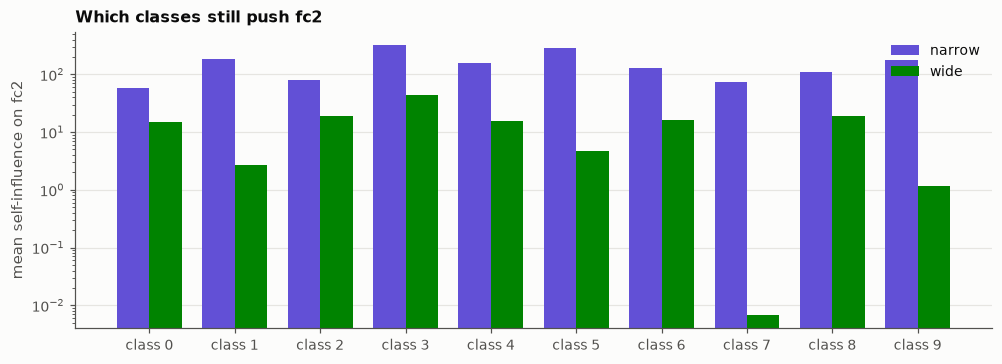

hardest example for narrow fc2: #81, true class 5, predicted 2


its_class  influence
kind              example                      
helps (proponent) 187              8      679.5
                  26               8      637.6
                  184              5      553.9
                  178              2      445.4
                  141              0      402.2
hurts (opponent)  116              4    -1521.0
                  4                3    -1382.2
                  63               2     -919.1
                  245              2     -827.8
                  17               1     -808.2

TracInCPFast vs TracInCP(fc2) self-influence ranking: Spearman 0.96
TracInCPFastRandProj top-5 proponents overlap with TracInCPFast: 26%  (0.0s)


In [3]:
si = {name: layer_push(WIDTH[name], CKPTS[name][EPOCHS], "fc2") for name in WIDTH}
fig, ax = plt.subplots(figsize=(9, 3.2))
for k, name in enumerate(["narrow", "wide"]):
    v = [si[name][PY == c].mean().item() for c in range(N_CLASSES)]
    ax.bar(np.arange(N_CLASSES) + (k - 0.5) * 0.38, v, width=0.38, color=MODEL_COLOR[name], label=name)
ax.set_yscale("log")
ax.set_xticks(range(N_CLASSES), [f"class {c}" for c in range(N_CLASSES)])
ax.grid(axis="x", visible=False)
ax.set_ylabel("mean self-influence on fc2")
ax.set_title("Which classes still push fc2", loc="left")
ax.legend(loc="upper right")
plt.show()

narrow_path = save_state(CKPTS["narrow"][EPOCHS])
tracin = TracInCP(NARROW, TensorDataset(PX, PY), [narrow_path], checkpoints_load_func=load_ckpt, layers=["fc2"],
                  loss_fn=nn.CrossEntropyLoss(reduction="sum"), batch_size=64, sample_wise_grads_per_batch=True)
hard = int(si["narrow"].argmax())
with torch.no_grad():
    pred = int(NARROW(PX[hard:hard + 1]).argmax())
print(f"hardest example for narrow fc2: #{hard}, true class {int(PY[hard])}, predicted {pred}")
rows = []
for kind, proponents in [("helps (proponent)", True), ("hurts (opponent)", False)]:
    res = tracin.influence((PX[hard:hard + 1], PY[hard:hard + 1]), k=6, proponents=proponents)
    for idx, score in zip(res.indices[0].tolist(), res.influence_scores[0].tolist()):
        if idx != hard:  # an example always helps itself most
            rows.append(dict(kind=kind, example=idx, its_class=int(PY[idx]), influence=round(score, 1)))
display(pd.DataFrame(rows).groupby("kind").head(5).set_index(["kind", "example"]))


class BruteForceNN(NearestNeighbors):
    """Exact nearest neighbours by dot product, instead of the default annoy index."""

    def setup(self, data):
        self.data = data.reshape(len(data), -1)

    def get_nearest_neighbors(self, query, k):
        scores, idx = (query.reshape(len(query), -1) @ self.data.T).topk(k, dim=1)
        return idx, scores


t0 = time.time()
fast = TracInCPFast(NARROW, NARROW.fc4, TensorDataset(PX, PY), [narrow_path], checkpoints_load_func=load_ckpt,
                    loss_fn=nn.CrossEntropyLoss(reduction="sum"), batch_size=64)
proj = TracInCPFastRandProj(NARROW, NARROW.fc4, TensorDataset(PX, PY), [narrow_path], checkpoints_load_func=load_ckpt,
                            loss_fn=nn.CrossEntropyLoss(reduction="sum"), batch_size=64,
                            nearest_neighbors=BruteForceNN(), projection_dim=8)
queries = (PX[:32], PY[:32])
top_fast = fast.influence(queries, k=5).indices
top_proj = proj.influence(queries, k=5).indices
overlap = np.mean([len(set(a.tolist()) & set(b.tolist())) / 5 for a, b in zip(top_fast, top_proj)])
print(f"TracInCPFast vs TracInCP(fc2) self-influence ranking: Spearman {spearman(fast.self_influence((PX, PY)), si['narrow']):.2f}")
print(f"TracInCPFastRandProj top-5 proponents overlap with TracInCPFast: {overlap:.0%}  ({time.time() - t0:.1f}s)")

* Every class still pushes the narrow `fc2`, some far more than others. In the wide model the push is far smaller
  for every class.
* The examples that most help or hurt the hardest example mostly belong to other classes. With only 3 units, classes
  have to share `fc2`'s directions, so fitting one class moves the others.
* `TracInCPFast` (last layer only) ranks examples much like the full per-layer TracInCP, at a fraction of the cost.
  `TracInCPFastRandProj` with only 8 projection dimensions finds about a quarter of the same top-5 proponents. Raise
  `projection_dim` for more accuracy.

## 19. `NaiveInfluenceFunction`: classic influence functions

```python
H = Hessian of the training loss w.r.t. fc2's weights      # 195 × 195 in narrow
influence[i, j] = g[i] · H⁻¹ · g[j]                        # TracInCP is the same without H⁻¹
```

"Naive" = it forms `H` explicitly, so it is used on the narrow `fc2` only (Koh & Liang, 2017).

NaiveInfluenceFunction in 0.1s; Spearman with TracInCP self-influence: 0.98


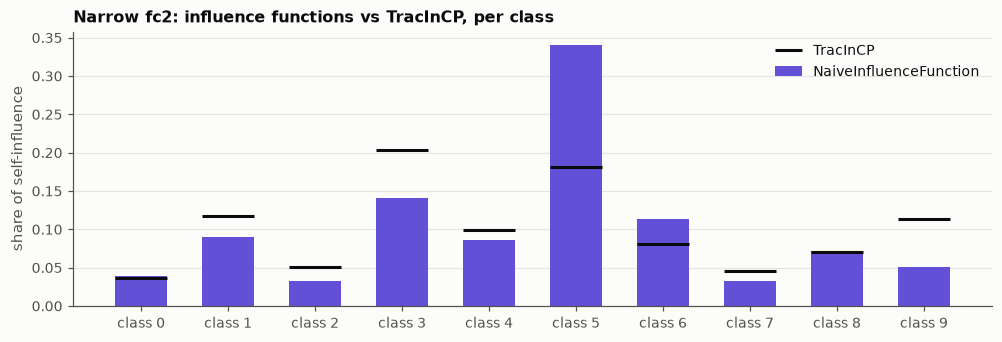

In [4]:
t0 = time.time()
nif = NaiveInfluenceFunction(NARROW, TensorDataset(PX, PY), narrow_path, checkpoints_load_func=load_ckpt,
                             layers=["fc2"], loss_fn=nn.CrossEntropyLoss(reduction="none"), batch_size=64,
                             projection_dim=None)
si_nif = nif.self_influence((PX, PY))
print(f"NaiveInfluenceFunction in {time.time() - t0:.1f}s; "
      f"Spearman with TracInCP self-influence: {spearman(si_nif, si['narrow']):.2f}")
fig, ax = plt.subplots(figsize=(9, 3))
for v, label, style in [(si_nif, "NaiveInfluenceFunction", "bar"), (si["narrow"], "TracInCP", "tick")]:
    per_class = torch.stack([v[PY == c].mean() for c in range(N_CLASSES)])
    per_class = (per_class / per_class.sum()).numpy()
    if style == "bar":
        ax.bar(range(N_CLASSES), per_class, color=MODEL_COLOR["narrow"], width=0.6, label=label)
    else:
        ax.hlines(per_class, np.arange(N_CLASSES) - 0.3, np.arange(N_CLASSES) + 0.3, color=INK, lw=2, label=label)
ax.set_xticks(range(N_CLASSES), [f"class {c}" for c in range(N_CLASSES)])
ax.grid(axis="x", visible=False)
ax.set_ylabel("share of self-influence")
ax.set_title("Narrow fc2: influence functions vs TracInCP, per class", loc="left")
ax.legend(loc="upper right")
plt.show()

The two rank individual examples almost identically. The Hessian shifts the weight between classes a little (more
on class 5, less on classes 3 and 9). On a model this size, TracInCP's cheaper gradient dot products give the same picture.

## 20. `SimilarityInfluence`: nearest training examples inside each layer

```python
for layer in [fc1, fc2, fc3, fc4]:
    a_train = layer output for 2000 training examples
    a_x     = layer output for one example
    nearest = the 10 training examples with the highest cosine(a_x, a_train)
    same_label = share of nearest with the same label as the example          → bar chart
```

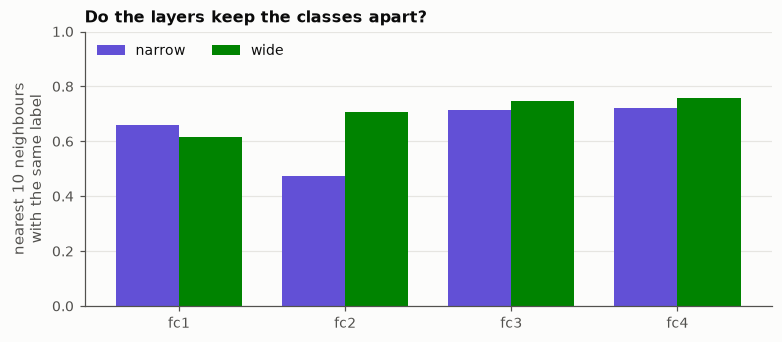

In [5]:
knn = {name: same_label_knn(name, model) for name, model in MODELS.items()}  # in toy.py
fig, ax = plt.subplots(figsize=(7, 3))
for k, name in enumerate(["narrow", "wide"]):
    ax.bar(np.arange(4) + (k - 0.5) * 0.38, knn[name], width=0.38, color=MODEL_COLOR[name], label=name)
ax.set_xticks(range(4), SIM_LAYERS)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 1)
ax.set_ylabel("nearest 10 neighbours\nwith the same label")
ax.legend(loc="upper left", ncol=2)
ax.set_title("Do the layers keep the classes apart?", loc="left")
plt.show()

In the narrow `fc2`, under half of each example's nearest neighbours share its label: the bottleneck squeezes
different classes onto the same activation patterns. Wide `fc2` keeps them apart as well as the other layers do.